In [182]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [183]:
GROUP = "C8"
DTYPE="GLCM"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C8_10,30,"[DATA/TRAINING/C8/C8_10/IMG_8678.HEIC, DATA/TR..."
1,C8_11,25,"[DATA/TRAINING/C8/C8_11/IMG_8730.HEIC, DATA/TR..."
2,C8_12,25,"[DATA/TRAINING/C8/C8_12/IMG_8761.HEIC, DATA/TR..."
3,C8_13,25,"[DATA/TRAINING/C8/C8_13/IMG_8793.HEIC, DATA/TR..."
4,C8_14,25,"[DATA/TRAINING/C8/C8_14/IMG_8823.HEIC, DATA/TR..."
5,C8_15,26,"[DATA/TRAINING/C8/C8_15/IMG_8855.HEIC, DATA/TR..."
6,C8_16,25,"[DATA/TRAINING/C8/C8_16/IMG_8886.HEIC, DATA/TR..."


In [184]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [185]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [186]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [187]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

Text(0.5, 1.0, '16% IMG_8904.HEIC')

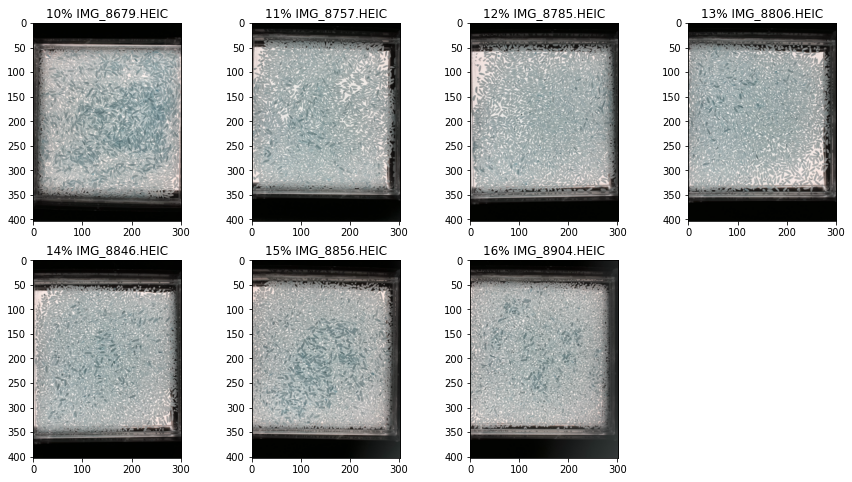

In [188]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [201]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [202]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,298.114419,600.261071,500.738936,623.891984,11.352434,16.282410,14.218487,16.595978,0.236722,0.163197,...,0.012015,0.009334,0.009168,0.009162,3,120,90,3,IMG_8678.HEIC,10
1,272.715637,509.249079,416.701774,512.701067,11.356086,15.468322,13.567134,15.567463,0.228378,0.166455,...,0.013497,0.010313,0.010229,0.010277,3,120,90,3,IMG_8679.HEIC,10
2,296.264794,538.128883,440.978245,549.020017,11.763483,16.143990,14.104855,16.363422,0.216901,0.158333,...,0.011335,0.008418,0.008475,0.008432,3,120,90,3,IMG_8680.HEIC,10
3,284.583427,476.544141,378.739216,480.575111,11.477434,15.597866,13.633520,15.755358,0.227437,0.164479,...,0.013142,0.009887,0.009795,0.009884,3,120,90,3,IMG_8682.HEIC,10
4,284.137547,486.519498,371.012792,480.512699,11.256648,15.198754,12.949486,15.238221,0.225055,0.163980,...,0.012095,0.009041,0.009028,0.009039,3,120,90,3,IMG_8686.HEIC,10
5,297.910019,587.897743,470.312605,591.449249,11.175562,15.923614,13.684781,16.002738,0.238127,0.170105,...,0.013442,0.010381,0.010276,0.010400,3,120,90,3,IMG_8693.HEIC,10
6,348.332584,659.685865,533.091783,664.952979,12.083521,17.091587,15.008683,17.322916,0.229091,0.161889,...,0.010060,0.007532,0.007425,0.007492,3,120,90,3,IMG_8701.HEIC,10
7,402.091292,722.580871,548.983660,725.183646,12.760019,18.075158,15.313072,18.087810,0.231024,0.159659,...,0.009910,0.007450,0.007445,0.007511,3,120,90,3,IMG_8702.HEIC,10
8,400.172285,640.155037,487.829412,659.909829,12.980524,17.526201,14.976377,17.750826,0.229675,0.156959,...,0.010808,0.008102,0.008099,0.008066,3,120,90,3,IMG_8703.HEIC,10
9,352.342697,598.519875,456.802614,587.196015,12.223034,16.648097,14.207283,16.467850,0.229669,0.165370,...,0.011712,0.008881,0.008806,0.008879,3,120,90,3,IMG_8704.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.738095,0.571429,0.644156,GLCM,C8,RF_C,3,120,90,3
1,2,0.722222,0.714286,0.714286,0.714286,GLCM,C8,RF_C,3,120,90,3
2,3,0.611111,0.726190,0.619048,0.668352,GLCM,C8,RF_C,3,120,90,3
3,4,0.500000,0.571429,0.547619,0.559271,GLCM,C8,RF_C,3,120,90,3
4,5,0.722222,0.823810,0.738095,0.778600,GLCM,C8,RF_C,3,120,90,3
5,6,0.888889,0.880952,0.880952,0.880952,GLCM,C8,RF_C,3,120,90,3
6,7,0.444444,0.564286,0.476190,0.516509,GLCM,C8,RF_C,3,120,90,3
7,8,0.666667,0.747619,0.690476,0.717912,GLCM,C8,RF_C,3,120,90,3
8,9,0.555556,0.652381,0.595238,0.622501,GLCM,C8,RF_C,3,120,90,3
9,10,0.500000,0.702381,0.523810,0.600092,GLCM,C8,RF_C,3,120,90,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C8,RF_C,0.619006,0.635714,0.670263,0.712143


### MLP Classifier

In [162]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [163]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.842105,0.800000,0.809524,0.804734,GLCM,C8,MLP_C,3,120,90,3
1,2,0.722222,0.761905,0.738095,0.749811,GLCM,C8,MLP_C,3,120,90,3
2,3,0.722222,0.761905,0.738095,0.749811,GLCM,C8,MLP_C,3,120,90,3
3,4,0.888889,0.916667,0.904762,0.910675,GLCM,C8,MLP_C,3,120,90,3
4,5,0.777778,0.866667,0.785714,0.824207,GLCM,C8,MLP_C,3,120,90,3
5,6,0.555556,0.559524,0.571429,0.565414,GLCM,C8,MLP_C,3,120,90,3
6,7,0.777778,0.833333,0.785714,0.808824,GLCM,C8,MLP_C,3,120,90,3
7,8,0.722222,0.795238,0.714286,0.752591,GLCM,C8,MLP_C,3,120,90,3
8,9,0.722222,0.773810,0.738095,0.755531,GLCM,C8,MLP_C,3,120,90,3
9,10,0.611111,0.678571,0.619048,0.647444,GLCM,C8,MLP_C,3,120,90,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C8,MLP_C,0.734211,0.740476,0.756904,0.774762


### XGBoost Classifier

In [166]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.535714,0.571429,0.552995,GLCM,C8,XGB_C,3,120,90,3
1,2,0.833333,0.833333,0.833333,0.833333,GLCM,C8,XGB_C,3,120,90,3
2,3,0.555556,0.580952,0.571429,0.576151,GLCM,C8,XGB_C,3,120,90,3
3,4,0.777778,0.833333,0.809524,0.821256,GLCM,C8,XGB_C,3,120,90,3
4,5,0.666667,0.773810,0.690476,0.729772,GLCM,C8,XGB_C,3,120,90,3
5,6,0.666667,0.728571,0.666667,0.696246,GLCM,C8,XGB_C,3,120,90,3
6,7,0.555556,0.630952,0.595238,0.612575,GLCM,C8,XGB_C,3,120,90,3
7,8,0.666667,0.788095,0.666667,0.722313,GLCM,C8,XGB_C,3,120,90,3
8,9,0.666667,0.702381,0.666667,0.684058,GLCM,C8,XGB_C,3,120,90,3
9,10,0.666667,0.690476,0.690476,0.690476,GLCM,C8,XGB_C,3,120,90,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C8,XGB_C,0.66345,0.67619,0.691918,0.709762


# External validation

In [169]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C8_10,5,"[DATA/TEST/C8/C8_10/IMG_8685.HEIC, DATA/TEST/C..."
1,C8_11,5,"[DATA/TEST/C8/C8_11/IMG_8732.HEIC, DATA/TEST/C..."
2,C8_12,5,"[DATA/TEST/C8/C8_12/IMG_8762.HEIC, DATA/TEST/C..."
3,C8_13,5,"[DATA/TEST/C8/C8_13/IMG_8792.HEIC, DATA/TEST/C..."
4,C8_14,5,"[DATA/TEST/C8/C8_14/IMG_8827.HEIC, DATA/TEST/C..."
5,C8_15,5,"[DATA/TEST/C8/C8_15/IMG_8854.HEIC, DATA/TEST/C..."
6,C8_16,5,"[DATA/TEST/C8/C8_16/IMG_8901.HEIC, DATA/TEST/C..."


In [170]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [171]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])

        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [172]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,344.381086,543.825323,415.202894,546.390331,12.235581,16.252479,13.988889,16.305920,0.224381,0.160958,...,0.012815,0.009650,0.009581,0.009629,3,120,90,3,IMG_8685.HEIC,10
1,264.875936,442.569351,352.707843,450.431404,10.876311,14.535549,12.568534,14.726183,0.227222,0.166782,...,0.011265,0.008394,0.008347,0.008358,3,120,90,3,IMG_8687.HEIC,10
2,270.633427,469.104900,370.438375,473.405344,10.829869,14.490039,12.490850,14.659617,0.230836,0.174673,...,0.012670,0.009718,0.009689,0.009720,3,120,90,3,IMG_8688.HEIC,10
3,339.781180,720.990936,587.353688,721.258521,11.989045,17.910584,15.648179,17.921348,0.242935,0.164107,...,0.011634,0.009009,0.009015,0.009030,3,120,90,3,IMG_8696.HEIC,10
4,280.266386,450.465301,361.274790,455.925786,10.822566,14.202436,12.589262,14.268908,0.233537,0.172325,...,0.011512,0.008701,0.008686,0.008743,3,120,90,3,IMG_8699.HEIC,10
0,407.629307,654.675762,497.844725,659.099802,13.151404,17.535549,15.072923,17.543952,0.222741,0.162716,...,0.010848,0.008366,0.008303,0.008422,3,120,90,3,IMG_8732.HEIC,11
1,402.155243,676.389387,530.555836,691.104145,13.090637,17.766405,15.257983,17.858937,0.232024,0.160965,...,0.011398,0.008748,0.008789,0.008736,3,120,90,3,IMG_8735.HEIC,11
2,403.365449,680.258805,542.926704,697.861769,13.039981,17.692852,15.539402,18.052875,0.225257,0.161607,...,0.011892,0.009050,0.008934,0.009017,3,120,90,3,IMG_8737.HEIC,11
3,285.138390,491.642904,410.933520,486.300255,10.955993,14.798414,13.161531,14.765933,0.235277,0.170370,...,0.010333,0.007862,0.007815,0.007880,3,120,90,3,IMG_8739.HEIC,11
4,339.156461,534.991502,371.682820,540.525541,11.353652,15.145595,12.407563,15.188179,0.237024,0.172808,...,0.010803,0.008244,0.008204,0.008268,3,120,90,3,IMG_8740.HEIC,11


In [173]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [174]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [175]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [176]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [177]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.38      0.60      0.46         5
     Class 1       0.67      0.40      0.50         5
     Class 2       0.67      0.40      0.50         5
     Class 3       0.25      0.20      0.22         5
     Class 4       0.22      0.40      0.29         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.67      0.40      0.50         5

    accuracy                           0.46        35
   macro avg       0.52      0.46      0.47        35
weighted avg       0.52      0.46      0.47        35



## MLP

In [178]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.17      0.20      0.18         5
     Class 1       0.40      0.40      0.40         5
     Class 2       0.25      0.20      0.22         5
     Class 3       0.75      0.60      0.67         5
     Class 4       0.38      0.60      0.46         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      0.60      0.75         5

    accuracy                           0.51        35
   macro avg       0.56      0.51      0.53        35
weighted avg       0.56      0.51      0.53        35



## XGBC

In [180]:
y_pred = modelXGBC.predict(X_test_scale) 

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.25      0.20      0.22         5
     Class 1       0.50      0.40      0.44         5
     Class 2       0.00      0.00      0.00         5
     Class 3       0.17      0.20      0.18         5
     Class 4       0.33      0.60      0.43         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.46        35
   macro avg       0.46      0.46      0.45        35
weighted avg       0.46      0.46      0.45        35

